# Notebook 16b — Manuscript figures: time, events, combinations, networks

Added November 2026 for the law review manuscript. This notebook draws the figures and writes the tables for Part IV.E (change over time), Part IV.F (events and combinations), and the supplement's Appendix B, in the single style of `saf_style.py`: prevalence blue, distinctiveness red, everything else gray, black intervals, upright plots, no figure titles.

The May 2026 draft built its temporal and combination results on the composite score. The paper no longer ranks anything by the composite, so each of those analyses is recomputed here on the two measures:

- **Survival** of a genre's conventions: of the 50 elements at the top of a genre in one five-year period, how many are still in the top 50 a given number of years later, computed separately for the top 50 by prevalence and the top 50 by distinctiveness.
- **Lifecycles**: an element's percentile within its genre, period by period, on each measure.
- **New entrants**: how many of each period's top-50 elements had never been in the genre's top 50 before.
- **Combinations**: pairs of elements that appear together, ranked by the pair's own distinctiveness (of the films with both elements, the share in the genre), with a minimum number of films. No composite enters.
- **Networks and centrality**: the strongest co-occurrence links, and how an element's centrality in its genre's network relates to each measure.

Nothing upstream is changed and no language model is called. Inputs are the saved tables of Notebooks 03, 03b, 03c, 08, 13 and 14. Outputs: figures in the manuscript's `figures/` folder (PDF and PNG), tables in its `tables/` folder, and the numbers in `v4_rebuild/16b_manuscript_figures/`.

In [1]:
import os, sys, math, shutil, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import networkx as nx
from scipy.stats import spearmanr, t as t_dist

try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
except Exception:
    pass

_CANDS = [
    Path('/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational'),
    Path('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/'
         'My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational'),
    Path.cwd().parent.parent, Path.cwd().parent,
]
PROJECT_ROOT = next((c for c in _CANDS if (c / 'Analysis' / 'v4_rebuild').exists()), None)
assert PROJECT_ROOT is not None, 'Could not locate the project folder; set PROJECT_ROOT manually.'
sys.path.insert(0, str(PROJECT_ROOT / 'Analysis' / 'notebooks'))
import saf_style as S
S.use()

V4 = PROJECT_ROOT / 'Analysis' / 'v4_rebuild'
OUT = V4 / '16b_manuscript_figures'
OUT.mkdir(parents=True, exist_ok=True)
FIG = S.manuscript_figures_dir(PROJECT_ROOT)
TAB = FIG.parent / 'tables'
TAB.mkdir(exist_ok=True)
TMP = Path(tempfile.mkdtemp())
def local_copy(p):
    q = TMP / p.name          # Drive sometimes serves partial parquet files; read a local copy
    if not q.exists():
        shutil.copy(p, q)
    return q
def read_parquet(p, **kw):
    return pd.read_parquet(local_copy(p), **kw)

report = []
def out(s=''):
    print(s); report.append(str(s))

def mean_ci(v):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) < 2:
        return (np.nan, np.nan)
    h = t_dist.ppf(.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean() - h, v.mean() + h

def wilson(k, n, z=1.96):
    k = np.asarray(k, float); n = np.asarray(n, float); p = k / n
    den = 1 + z ** 2 / n; c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h

def tex(s):
    s = str(s)
    for a, b in [('\\', r'\textbackslash{}'), ('&', r'\&'), ('%', r'\%'), ('$', r'\$'), ('#', r'\#'), ('_', r'\_'), ('{', r'\{'), ('}', r'\}')]:
        s = s.replace(a, b)
    return s

def write_table(name, caption, label, colspec, header, rows, note, long=False):
    # booktabs table with a footnotesize note underneath; upright; the manuscript inputs it unchanged
    body = '\n'.join(' & '.join(r) + r' \\' for r in rows)
    if not long:
        s = (r'\begin{table}[htbp]' '\n' r'\centering' '\n' rf'\caption{{{caption}}}' '\n' rf'\label{{{label}}}' '\n'
             r'\small' '\n' rf'\begin{{tabular}}{{{colspec}}}' '\n' r'\toprule' '\n' + header + r' \\' '\n' r'\midrule' '\n'
             + body + '\n' r'\bottomrule' '\n' r'\end{tabular}' '\n\n' r'\medskip' '\n'
             r'\begin{minipage}{0.95\textwidth}\footnotesize' '\n' rf'\emph{{Note:}} {note}' '\n' r'\end{minipage}' '\n' r'\end{table}' '\n')
    else:
        s = (r'{\small' '\n' rf'\begin{{longtable}}{{{colspec}}}' '\n' rf'\caption{{{caption}}}\label{{{label}}}\\' '\n'
             r'\toprule' '\n' + header + r' \\' '\n' r'\midrule' '\n' r'\endfirsthead' '\n'
             r'\toprule' '\n' + header + r' \\' '\n' r'\midrule' '\n' r'\endhead' '\n'
             r'\bottomrule' '\n' r'\endlastfoot' '\n'
             + body + '\n' r'\end{longtable}' '\n' r'}' '\n'
             rf'{{\footnotesize\noindent\emph{{Note:}} {note}\par}}' '\n')   # note below the table, so it never widens it
    (TAB / f'{name}.tex').write_text(s)
    print('wrote', TAB / f'{name}.tex')

SIX = ['Western', 'Horror', 'Science Fiction', 'Crime', 'Fantasy', 'Comedy']
print('project:', PROJECT_ROOT); print('figures ->', FIG); print('tables ->', TAB)

project: /Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational
figures -> /Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures
tables -> /Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/tables


## Inputs

The narrative vocabulary is the 17,965 element-type pairs the classifier kept (after the franchise blocklist), as frozen for Study 1 in `10_human_study_stimuli/coding_vocabulary.csv`. Films per genre come from the union corpus.

In [2]:
narr = pd.read_csv(V4 / '10_human_study_stimuli' / 'coding_vocabulary.csv')[['element', 'element_type']]
NARR = set(map(tuple, narr.values))
union = read_parquet(V4 / '01c_union' / 'movies_union.parquet', columns=['union_id', 'year', 'genres_canonical'])
N_g = pd.Series([g for gs in union['genres_canonical'] for g in gs]).value_counts()
GENRES = sorted(N_g.index)
sl = read_parquet(V4 / '03b_classification' / 'stockiness_long_classified.parquet',
                  columns=['element', 'element_type', 'genre', 'film_count', 'total_film_count', 'rel_freq_in_genre', 'posterior_smoothed'])
sl = sl[[k in NARR for k in zip(sl['element'], sl['element_type'])]].copy()
out(f'narrative pairs: {len(NARR):,}; genres: {len(GENRES)}; films: {len(union):,}')
out('films per genre: ' + ', '.join(f'{g} {N_g[g]:,}' for g in GENRES))

narrative pairs: 17,965; genres: 17; films: 45,958
films per genre: Action 7,775, Adventure 6,146, Animation 2,835, Comedy 14,724, Crime 5,564, Drama 22,364, Family 4,164, Fantasy 2,429, History 2,882, Horror 4,363, Music 2,926, Mystery 2,681, Romance 8,220, Science Fiction 2,590, Thriller 7,447, War 1,658, Western 1,362


## Part IV.E (1): the odds ratio between element and genre, before 1970 and from 1990 on

From Notebook 14 (`association_over_time.parquet`): for each signature element, the median odds ratio over five-year periods before 1970 and from 1990 on (periods with at least 30 films in the genre and 5 films with the element). The odds ratio does not depend on how large the genre is. A value of 1 means no association.


E1. Odds ratio, median before 1970 / from 1990 on
  sheriff    Western              24 / 17      distinctiveness 0.61 / 0.14  genre share 0.067 / 0.010
  outlaw     Western              65 / 66      distinctiveness 0.80 / 0.39  genre share 0.067 / 0.010
  vampire    Horror              131 / 35      distinctiveness 0.93 / 0.82  genre share 0.077 / 0.101
  ghost      Horror                7 / 12      distinctiveness 0.22 / 0.54  genre share 0.052 / 0.101
  detective  Crime                 6 / 6       distinctiveness 0.44 / 0.48  genre share 0.114 / 0.139
  gangster   Crime                 7 / 5       distinctiveness 0.44 / 0.44  genre share 0.114 / 0.139
  planet     Science Fiction      94 / 36      distinctiveness 0.84 / 0.69  genre share 0.067 / 0.066
  alien      Science Fiction     147 / 37      distinctiveness 0.93 / 0.70  genre share 0.067 / 0.066
  wizard     Fantasy              21 / 18      distinctiveness 0.50 / 0.55  genre share 0.047 / 0.068
  witch      Fantasy           

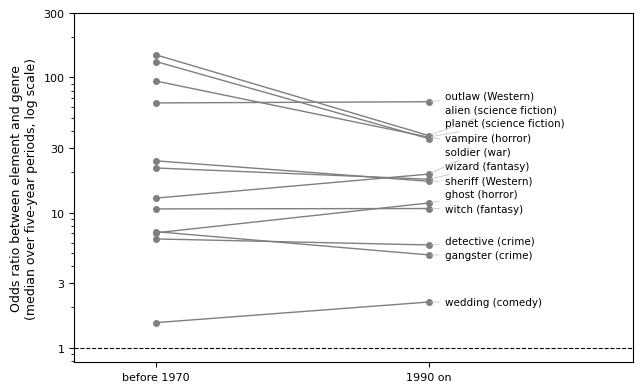

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_odds_ratio_early_late.pdf')

In [3]:
assoc = read_parquet(V4 / '14_dimension_checks' / 'association_over_time.parquet')
SHORT = {'Western': 'Western', 'Horror': 'horror', 'Crime': 'crime', 'Science Fiction': 'science fiction',
         'Fantasy': 'fantasy', 'Comedy': 'comedy', 'War': 'war'}
rows = []
for (el, g), d in assoc.groupby(['element', 'genre'], sort=False):
    early, late = d[d['bin'] < 1970], d[d['bin'] >= 1990]
    if len(early) and len(late):
        rows.append({'element': el, 'genre': g, 'or_early': early['odds_ratio'].median(), 'or_late': late['odds_ratio'].median(),
                     'dist_early': early['distinctiveness'].median(), 'dist_late': late['distinctiveness'].median(),
                     'share_early': early['genre_share'].median(), 'share_late': late['genre_share'].median()})
orx = pd.DataFrame(rows)
orx.to_csv(OUT / 'odds_ratio_early_late.csv', index=False)
out('\nE1. Odds ratio, median before 1970 / from 1990 on')
for r in orx.itertuples():
    out(f'  {r.element:<10} {r.genre:<16} {r.or_early:6.0f} / {r.or_late:<6.0f}  distinctiveness {r.dist_early:.2f} / {r.dist_late:.2f}  genre share {r.share_early:.3f} / {r.share_late:.3f}')

fig, ax = plt.subplots(figsize=S.size(1.0, 4.0))
o = orx.sort_values('or_late')
for r in o.itertuples():
    ax.plot([0, 1], [r.or_early, r.or_late], '-o', color=S.NEUTRAL, ms=4, lw=1)
# labels on the right, nudged apart so they do not overlap
ys = np.log10(o['or_late'].values); lab_y = ys.copy()
for i in range(1, len(lab_y)):
    lab_y[i] = max(lab_y[i], lab_y[i - 1] + 0.105)
for r, ly in zip(o.itertuples(), lab_y):
    ax.annotate(f'{r.element} ({SHORT.get(r.genre, r.genre)})', xy=(1, r.or_late), xytext=(1.06, 10 ** ly),
                va='center', fontsize=7.5, arrowprops=dict(arrowstyle='-', color=S.LIGHT, lw=0.6))
ax.axhline(1, color=S.INK, ls='--', lw=0.8)
ax.set_yscale('log'); ax.set_yticks([1, 3, 10, 30, 100, 300]); ax.set_yticklabels(['1', '3', '10', '30', '100', '300'])
ax.set_xticks([0, 1]); ax.set_xticklabels(['before 1970', '1990 on']); ax.set_xlim(-0.3, 1.75)
ax.set_ylabel('Odds ratio between element and genre\n(median over five-year periods, log scale)')
S.save(fig, 'fig_odds_ratio_early_late', FIG)

## Part IV.E (2): three elements over time

Prevalence (blue), distinctiveness (red) and the genre's share of all films (gray, dashed), by five-year period from 1930. The panel title gives the odds ratio before 1970 and from 1990 on.

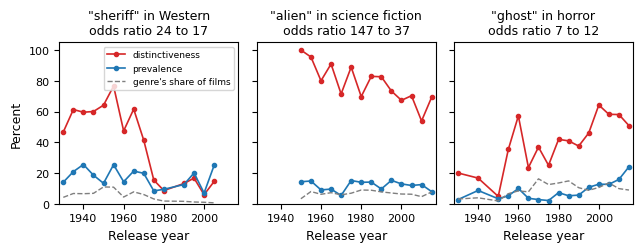

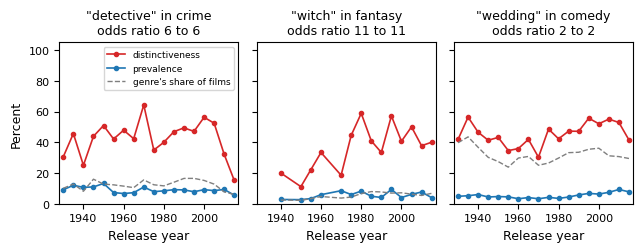

In [4]:
def over_time(panels, name):
    fig, axes = plt.subplots(1, 3, figsize=S.size(1.0, 2.6), sharey=True)
    for ax, (el, g) in zip(axes, panels):
        d = assoc[(assoc['element'] == el) & (assoc['genre'] == g) & (assoc['bin'] >= 1930)].sort_values('bin')
        ax.plot(d['bin'], 100 * d['distinctiveness'], 'o-', ms=3, lw=1.2, color=S.DISTINCTIVENESS, label='distinctiveness')
        ax.plot(d['bin'], 100 * d['prevalence'], 'o-', ms=3, lw=1.2, color=S.PREVALENCE, label='prevalence')
        ax.plot(d['bin'], 100 * d['genre_share'], '--', lw=1, color=S.NEUTRAL, label="genre's share of films")
        e, l = d[d['bin'] < 1970]['odds_ratio'].median(), d[d['bin'] >= 1990]['odds_ratio'].median()
        ax.set_title(f'"{el}" in {SHORT[g]}\nodds ratio {e:.0f} to {l:.0f}')
        ax.set_xlabel('Release year'); ax.set_ylim(0, 105); ax.set_xlim(1928, 2017); ax.set_xticks([1940, 1960, 1980, 2000])
    axes[0].set_ylabel('Percent'); axes[0].legend(loc='upper right', fontsize=6.5, frameon=True)
    S.save(fig, name, FIG)
over_time([('sheriff', 'Western'), ('alien', 'Science Fiction'), ('ghost', 'Horror')], 'fig_over_time_three')
over_time([('detective', 'Crime'), ('witch', 'Fantasy'), ('wedding', 'Comedy')], 'fig_over_time_three_more')

## Part IV.E (3): survival of a genre's top 50, on each measure

Per-period scores come from Notebook 08 (`stockiness_by_bin.parquet`), which recomputes every measure inside each five-year period. Here:

- a period counts for a genre if the genre has at least 100 films in it and at least 150 eligible elements;
- an element is eligible in a genre and period if it is a narrative element in at least 5 of the genre's films in that period (this keeps distinctiveness from being driven by an element seen once);
- the top 50 is taken separately by prevalence (`rel_freq_in_genre`) and by distinctiveness (`posterior_smoothed`, α = 1, prior from the period's genre shares);
- survival at a lag of k periods is the share of a period's top 50 that is still in the top 50 k periods later, averaged over the genre's starting periods; the corpus value is the mean over genres, with a 95% t interval across genres.

The May 2026 draft instead followed elements above z = 1 on the composite. The chance level printed beside each value is 50 divided by the number of eligible elements in the later period: the share expected if the later top 50 were drawn at random.


E3. Survival of the top 50 (mean over genres, 95% interval across genres; chance in brackets)
  qualifying genre-periods: 223; eligible element-periods: 221,440
  distinctiveness lag  5 years: 0.230 [0.158, 0.302]  chance 0.078  (17 genres)
  distinctiveness lag 10 years: 0.200 [0.131, 0.269]  chance 0.081  (17 genres)
  distinctiveness lag 15 years: 0.180 [0.111, 0.248]  chance 0.075  (17 genres)
  distinctiveness lag 20 years: 0.138 [0.092, 0.183]  chance 0.064  (15 genres)
  distinctiveness lag 25 years: 0.139 [0.093, 0.184]  chance 0.071  (16 genres)
  distinctiveness lag 30 years: 0.122 [0.075, 0.170]  chance 0.072  (15 genres)
  distinctiveness lag 35 years: 0.133 [0.072, 0.193]  chance 0.072  (16 genres)
  distinctiveness lag 40 years: 0.115 [0.062, 0.168]  chance 0.061  (15 genres)
  distinctiveness lag 45 years: 0.099 [0.045, 0.153]  chance 0.056  (15 genres)
  distinctiveness lag 50 years: 0.098 [0.048, 0.148]  chance 0.051  (15 genres)
  prevalence      lag  5 years: 0.831 

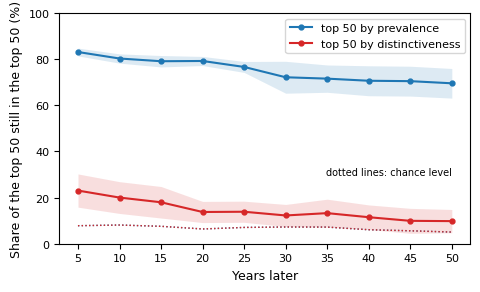

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_survival_two_measures.pdf')

In [5]:
bins = read_parquet(V4 / '08_temporal' / 'stockiness_by_bin.parquet',
                    columns=['element', 'element_type', 'genre', 'bin', 'film_count', 'N_bg', 'N_bin', 'rel_freq_in_genre', 'posterior_smoothed'])
bins = bins[[k in NARR for k in zip(bins['element'], bins['element_type'])]]
MIN_E, MIN_GENRE_FILMS, MIN_ELIGIBLE, TOP = 5, 100, 150, 50
elig = bins[bins['film_count'] >= MIN_E].copy()
n_elig = elig.groupby(['genre', 'bin']).size().rename('n_eligible')
nbg = bins.groupby(['genre', 'bin'])['N_bg'].first()
qual = pd.concat([n_elig, nbg], axis=1).reset_index()
qual = qual[(qual['N_bg'] >= MIN_GENRE_FILMS) & (qual['n_eligible'] >= MIN_ELIGIBLE)]
QUAL = set(zip(qual['genre'], qual['bin']))
elig = elig[[k in QUAL for k in zip(elig['genre'], elig['bin'])]]
MCOL = {'prevalence': 'rel_freq_in_genre', 'distinctiveness': 'posterior_smoothed'}
for m, c in MCOL.items():
    elig[f'pct_{m}'] = elig.groupby(['genre', 'bin'])[c].rank(pct=True)
tops = {m: {(g, b): set(zip(d.nlargest(TOP, c)['element'], d.nlargest(TOP, c)['element_type']))
            for (g, b), d in elig.groupby(['genre', 'bin'])} for m, c in MCOL.items()}
LAGS = list(range(1, 11))
surv = []
for m in MCOL:
    for g in GENRES:
        bs = sorted(b for (gg, b) in tops[m] if gg == g)
        for k in LAGS:
            vals, chance = [], []
            for b in bs:
                b2 = b + 5 * k
                if (g, b2) in tops[m]:
                    vals.append(len(tops[m][(g, b)] & tops[m][(g, b2)]) / TOP)
                    chance.append(TOP / n_elig[(g, b2)])
            if vals:
                surv.append({'measure': m, 'genre': g, 'lag_years': 5 * k, 'n_starts': len(vals),
                             'survival': np.mean(vals), 'chance': np.mean(chance)})
surv = pd.DataFrame(surv)
surv.to_csv(OUT / 'survival_two_measures.csv', index=False)
corp = []
for (m, k), d in surv.groupby(['measure', 'lag_years']):
    lo, hi = mean_ci(d['survival'])
    corp.append({'measure': m, 'lag_years': k, 'survival': d['survival'].mean(), 'lo': lo, 'hi': hi,
                 'chance': d['chance'].mean(), 'n_genres': len(d)})
corp = pd.DataFrame(corp)
corp.to_csv(OUT / 'survival_two_measures_corpus.csv', index=False)
out(f'\nE3. Survival of the top {TOP} (mean over genres, 95% interval across genres; chance in brackets)')
out(f'  qualifying genre-periods: {len(QUAL)}; eligible element-periods: {len(elig):,}')
for r in corp.itertuples():
    out(f'  {r.measure:<15} lag {r.lag_years:>2} years: {r.survival:.3f} [{r.lo:.3f}, {r.hi:.3f}]  chance {r.chance:.3f}  ({r.n_genres} genres)')

fig, ax = plt.subplots(figsize=S.size(0.75, 3.0))
for m, col in [('prevalence', S.PREVALENCE), ('distinctiveness', S.DISTINCTIVENESS)]:
    d = corp[corp['measure'] == m]
    ax.fill_between(d['lag_years'], 100 * d['lo'], 100 * d['hi'], color=col, alpha=0.15, lw=0)
    ax.plot(d['lag_years'], 100 * d['survival'], 'o-', ms=3.5, color=col, label=f'top 50 by {m}')
    ax.plot(d['lag_years'], 100 * d['chance'], ':', color=col, lw=1)
ax.set_xlabel('Years later'); ax.set_ylabel('Share of the top 50 still in the top 50 (%)')
ax.set_ylim(0, 100); ax.set_xticks(range(5, 55, 5))
ax.legend(loc='upper right'); ax.text(50, 30, 'dotted lines: chance level', ha='right', fontsize=7)
S.save(fig, 'fig_survival_two_measures', FIG)

### Appendix B: survival genre by genre

The same curves for each of the seventeen genres. Genres with few qualifying periods have short curves.

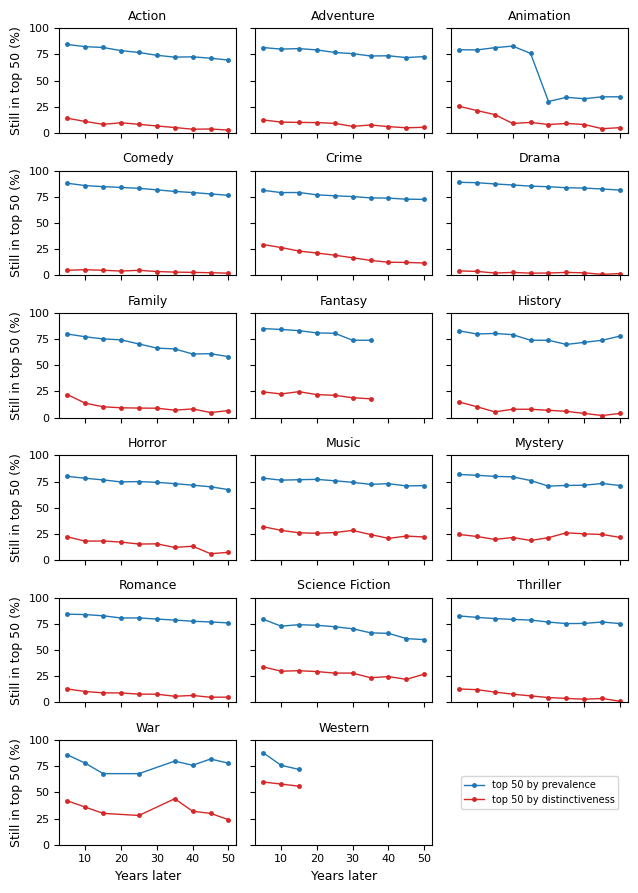

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_app_survival_by_genre.pdf')

In [6]:
fig, axes = plt.subplots(6, 3, figsize=S.size(1.0, 9.0), sharex=True, sharey=True)
for ax, g in zip(axes.flat, GENRES):
    for m, col in [('prevalence', S.PREVALENCE), ('distinctiveness', S.DISTINCTIVENESS)]:
        d = surv[(surv['measure'] == m) & (surv['genre'] == g)]
        ax.plot(d['lag_years'], 100 * d['survival'], 'o-', ms=2.5, lw=1, color=col, label=m)
    ax.set_title(g); ax.set_ylim(0, 100); ax.set_xticks([10, 20, 30, 40, 50])
for ax in axes.flat[len(GENRES):]:
    ax.axis('off')
h, l = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(h, [f'top 50 by {x}' for x in l], loc='center', fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel('Still in top 50 (%)')
for ax in axes[-1, :]:
    ax.set_xlabel('Years later')
axes.flat[len(GENRES) - 1].set_xlabel('Years later'); axes.flat[len(GENRES) - 1].xaxis.set_tick_params(labelbottom=True)
S.save(fig, 'fig_app_survival_by_genre', FIG)

## Part IV.E (4): lifecycles of six elements

An element's percentile within its genre in each five-year period, among the eligible elements of that genre and period (narrative elements in at least 5 of the genre's films that period), on prevalence (blue) and distinctiveness (red). A period counts if the genre has at least 50 films and 50 eligible elements in it. Gaps are periods in which the element was in fewer than 5 of the genre's films.

/var/folders/3l/l0_mn_f54n54ct0v8g0h24y40000gn/T/ipykernel_75580/3213698707.py:6: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.
  elig_l = bins[(bins['film_count'] >= MIN_E) & [k in QUAL_L for k in zip(bins['genre'], bins['bin'])]].copy()



E4. Lifecycles: percentile within genre by period (prevalence / distinctiveness)
  sheriff    Western          periods 9; 1930: 61/87; 1945: 91/93; 1960: 66/90
  saloon     Western          periods 8; 1935: 64/87; 1950: 87/92; 1965: 79/98
  vampire    Horror           periods 13; 1955: 48/100; 1970: 94/100; 1985: 84/100; 2000: 85/100; 2015: 11/99
  ghost      Horror           periods 12; 1940: 15/76; 1970: 39/71; 1990: 76/88; 2005: 97/94
  alien      Science Fiction  periods 14; 1950: 70/99; 1965: 69/98; 1980: 90/96; 1995: 95/99; 2010: 91/99
  detective  Crime            periods 18; 1930: 71/85; 1945: 90/91; 1960: 68/97; 1975: 79/90; 1990: 92/95; 2005: 95/97


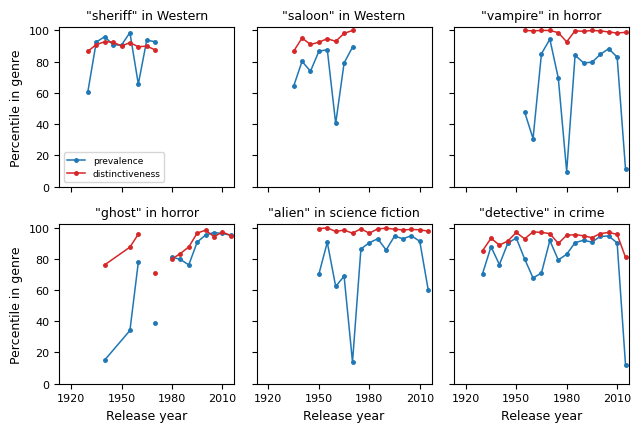

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_lifecycles_six.pdf')

In [7]:
# Lifecycles use a looser rule than survival, since they follow one element rather than a top 50:
# a period counts if the genre has at least 50 films and 50 eligible elements in it.
qual_l = pd.concat([n_elig, nbg], axis=1).reset_index()
qual_l = qual_l[(qual_l['N_bg'] >= 50) & (qual_l['n_eligible'] >= 50)]
QUAL_L = set(zip(qual_l['genre'], qual_l['bin']))
elig_l = bins[(bins['film_count'] >= MIN_E) & [k in QUAL_L for k in zip(bins['genre'], bins['bin'])]].copy()
for m, c in MCOL.items():
    elig_l[f'pct_{m}'] = elig_l.groupby(['genre', 'bin'])[c].rank(pct=True)
def life(el, g, et='noun'):
    d = elig_l[(elig_l['element'] == el) & (elig_l['genre'] == g) & (elig_l['element_type'] == et)].set_index('bin')
    allb = sorted(b for (gg, b) in QUAL_L if gg == g)
    return d.reindex(allb)

CANON = [('sheriff', 'Western'), ('saloon', 'Western'), ('vampire', 'Horror'), ('ghost', 'Horror'),
         ('alien', 'Science Fiction'), ('detective', 'Crime')]
fig, axes = plt.subplots(2, 3, figsize=S.size(1.0, 4.4), sharex=True, sharey=True)
out('\nE4. Lifecycles: percentile within genre by period (prevalence / distinctiveness)')
for ax, (el, g) in zip(axes.flat, CANON):
    d = life(el, g)
    ax.plot(d.index, 100 * d['pct_prevalence'], 'o-', ms=2.5, lw=1.1, color=S.PREVALENCE, label='prevalence')
    ax.plot(d.index, 100 * d['pct_distinctiveness'], 'o-', ms=2.5, lw=1.1, color=S.DISTINCTIVENESS, label='distinctiveness')
    ax.set_title(f'"{el}" in {SHORT[g]}'); ax.set_ylim(0, 102); ax.set_xlim(1913, 2017); ax.set_xticks([1920, 1950, 1980, 2010])
    ok = d.dropna(subset=['pct_prevalence'])
    out(f'  {el:<10} {g:<16} periods {len(ok)}; ' + '; '.join(f'{b}: {100*r.pct_prevalence:.0f}/{100*r.pct_distinctiveness:.0f}' for b, r in ok.iloc[::3].iterrows()))
axes[0, 0].legend(loc='lower left', fontsize=6.5)
for ax in axes[:, 0]:
    ax.set_ylabel('Percentile in genre')
for ax in axes[1, :]:
    ax.set_xlabel('Release year')
S.save(fig, 'fig_lifecycles_six', FIG)

### Appendix B: one signature element per genre

For each genre, the narrative noun with the highest distinctiveness over the whole corpus among those in at least 5% of the genre's films, followed period by period on both measures.


Appendix B signature elements: Action: henchman, Adventure: ship, Animation: mouse, Comedy: date, Crime: robbery, Drama: affair, Family: cat, Fantasy: magic, History: troop, Horror: zombie, Music: concert, Mystery: suspect, Romance: wedding, Science Fiction: spaceship, Thriller: suspect, War: german, Western: stagecoach


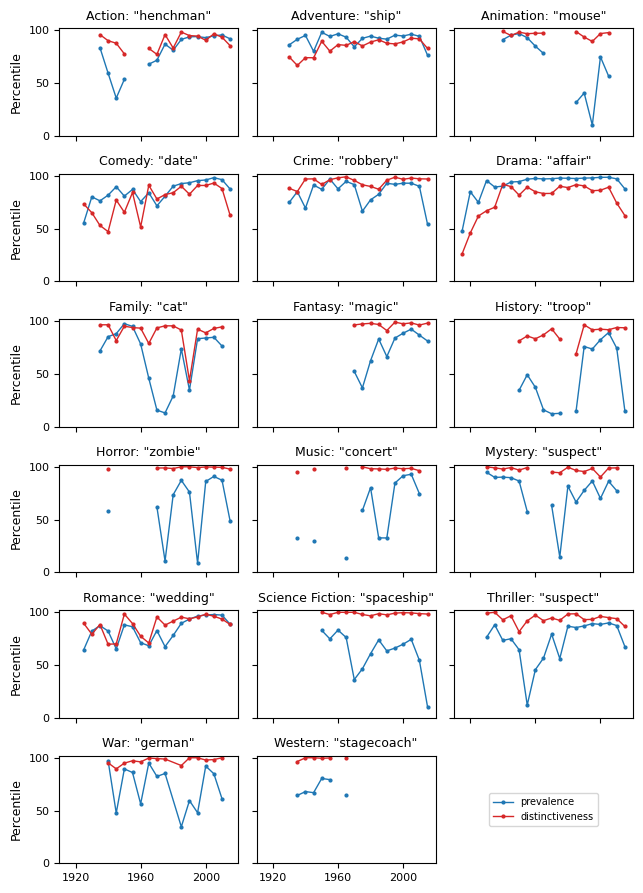

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_app_lifecycles_by_genre.pdf')

In [8]:
sig = []
for g in GENRES:
    d = sl[(sl['genre'] == g) & (sl['element_type'] == 'noun') & (sl['rel_freq_in_genre'] >= 0.05)]
    if len(d):
        sig.append((d.nlargest(1, 'posterior_smoothed')['element'].iloc[0], g))
fig, axes = plt.subplots(6, 3, figsize=S.size(1.0, 9.0), sharex=True, sharey=True)
for ax, (el, g) in zip(axes.flat, sig):
    d = life(el, g)
    ax.plot(d.index, 100 * d['pct_prevalence'], 'o-', ms=2, lw=1, color=S.PREVALENCE, label='prevalence')
    ax.plot(d.index, 100 * d['pct_distinctiveness'], 'o-', ms=2, lw=1, color=S.DISTINCTIVENESS, label='distinctiveness')
    ax.set_title(f'{g}: "{el}"'); ax.set_ylim(0, 102); ax.set_xticks([1920, 1960, 2000])
for ax in axes.flat[len(sig):]:
    ax.axis('off')
h, l = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(h, l, loc='center', fontsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel('Percentile')
axes.flat[len(sig) - 1].xaxis.set_tick_params(labelbottom=True)
out('\nAppendix B signature elements: ' + ', '.join(f'{g}: {el}' for el, g in sig))
S.save(fig, 'fig_app_lifecycles_by_genre', FIG)

## Part IV.E (5): new entrants to a genre's top 50

For each measure and five-year period, the share of the period's top-50 slots (pooled over genres) held by elements that had never been in that genre's top 50 in any earlier qualifying period. A genre's first qualifying period is left out, since everything is new there.

Caveat: the corpus grows over time (from a few hundred films per period before 1930 to several thousand after 2000), and plot summaries of recent films are longer and more detailed. More eligible elements in later periods mean more candidates for the top 50, so a higher entry rate in recent periods is partly a property of the corpus, not only of the genres.


E5. Share of top-50 slots held by new entrants (prevalence / distinctiveness)
  1920: 0.22 / 0.90
  1925: 0.16 / 0.88
  1930: 0.18 / 0.95
  1935: 0.16 / 0.80
  1940: 0.17 / 0.73
  1945: 0.13 / 0.69
  1950: 0.10 / 0.64
  1955: 0.10 / 0.58
  1960: 0.09 / 0.58
  1965: 0.10 / 0.58
  1970: 0.06 / 0.69
  1975: 0.09 / 0.58
  1980: 0.09 / 0.65
  1985: 0.09 / 0.63
  1990: 0.05 / 0.60
  1995: 0.03 / 0.62
  2000: 0.03 / 0.65
  2005: 0.01 / 0.66
  2010: 0.02 / 0.55
  2015: 0.06 / 0.56


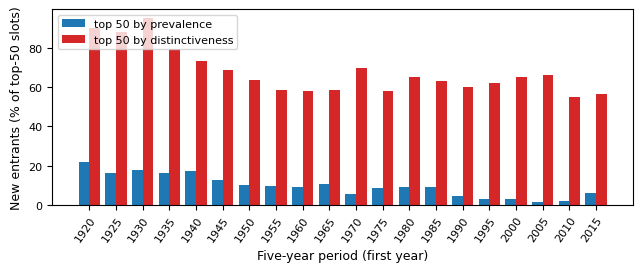

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_new_entrants.pdf')

In [9]:
ent = []
for m in MCOL:
    seen = {}
    for (g, b) in sorted(tops[m], key=lambda x: (x[0], x[1])):
        if g not in seen:
            seen[g] = set(tops[m][(g, b)]); continue
        new = tops[m][(g, b)] - seen[g]
        ent.append({'measure': m, 'genre': g, 'bin': b, 'new': len(new)})
        seen[g] |= tops[m][(g, b)]
ent = pd.DataFrame(ent)
rate = ent.groupby(['measure', 'bin']).agg(new=('new', 'sum'), genres=('genre', 'size')).reset_index()
rate['share_new'] = rate['new'] / (TOP * rate['genres'])
rate.to_csv(OUT / 'new_entrants_by_period.csv', index=False)
out('\nE5. Share of top-50 slots held by new entrants (prevalence / distinctiveness)')
pv = rate.pivot(index='bin', columns='measure', values='share_new')
for b, r in pv.iterrows():
    out(f'  {b}: {r.get("prevalence", np.nan):.2f} / {r.get("distinctiveness", np.nan):.2f}')
fig, ax = plt.subplots(figsize=S.size(1.0, 2.8))
x = np.arange(len(pv)); w = 0.4
ax.bar(x - w / 2, 100 * pv['prevalence'], w, color=S.PREVALENCE, label='top 50 by prevalence')
ax.bar(x + w / 2, 100 * pv['distinctiveness'], w, color=S.DISTINCTIVENESS, label='top 50 by distinctiveness')
ax.set_xticks(x); ax.set_xticklabels([str(b) for b in pv.index], rotation=55, ha='right', rotation_mode='anchor')
ax.set_ylabel('New entrants (% of top-50 slots)'); ax.set_xlabel('Five-year period (first year)')
ax.legend(loc='upper left')
S.save(fig, 'fig_new_entrants', FIG)

## Part IV.F (6): the most characteristic events

From Notebook 13: for each genre, the five events with the highest distinctiveness among those in at least 1% of the genre's films (minimum 8 films). The bar is distinctiveness: of the films with the event, the percentage in this genre. The counts above each bar are films in this genre over all films with the event; the black line is a 95% Wilson interval.


F6. Most characteristic events
  Western: rob stagecoach 18/18; form posse 19/22; ride into town 53/65; steal cattle 18/25; return to ranch 17/27
  Horror: turn into vampire 59/64; turn into zombie 53/60; drink blood 64/76; spirit possess 60/77; creature attack 47/68
  Science Fiction: destroy planet 35/48; kill creature 31/48; destroy ship 59/94; creature kill 27/46; travel in time 33/60


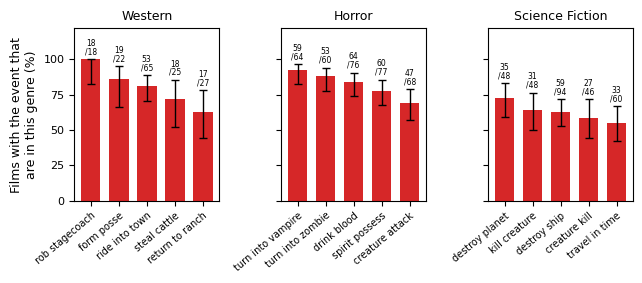

  Crime: investigate murder 91/200; find killer 57/125; solve case 66/155; commit crime 92/218; commit murder 121/291
  Fantasy: break spell 41/59; cast spell 39/67; use magic 74/132; return to form 25/44; return to world 37/75
  Comedy: throw party 151/258; get job 396/879; lose job 178/409; get money 187/446; spend day 168/406


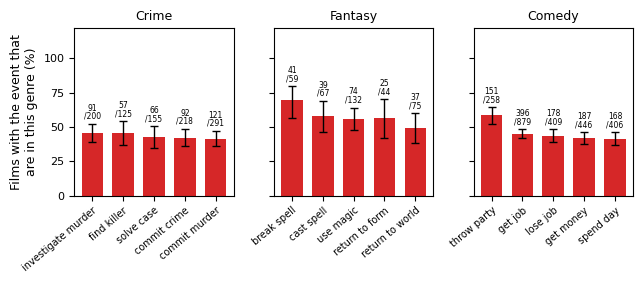

In [10]:
top_ev = read_parquet(V4 / '13_event_elements' / 'top_events_by_genre.parquet')
def event_bars(genres, name):
    fig, axes = plt.subplots(1, 3, figsize=S.size(1.0, 2.9), sharey=True)
    for ax, g in zip(axes, genres):
        d = top_ev[(top_ev['genre'] == g) & (top_ev['list'] == 'characteristic')].head(5)
        share = 100 * d['film_count'] / d['total_film_count']
        lo, hi = wilson(d['film_count'], d['total_film_count'])
        ax.bar(d['event'], share, color=S.DISTINCTIVENESS, width=0.7, yerr=[share - 100 * lo, 100 * hi - share], error_kw=S.ERR)
        for i, r in enumerate(d.itertuples()):
            ax.text(i, 100 * hi[i] + 2, f'{r.film_count}\n/{r.total_film_count}', ha='center', va='bottom', fontsize=5.5, linespacing=0.9)
        ax.set_ylim(0, 122); ax.set_yticks([0, 25, 50, 75, 100]); ax.set_title(g)
        plt.setp(ax.get_xticklabels(), rotation=40, ha='right', rotation_mode='anchor', fontsize=7)
        out(f'  {g}: ' + '; '.join(f'{r.event} {r.film_count}/{r.total_film_count}' for r in d.itertuples()))
    axes[0].set_ylabel('Films with the event that\nare in this genre (%)')
    S.save(fig, name, FIG)
out('\nF6. Most characteristic events')
event_bars(['Western', 'Horror', 'Science Fiction'], 'fig_events_three_genres')
event_bars(['Crime', 'Fantasy', 'Comedy'], 'fig_events_three_more')

## Part IV.F (7): events on both dimensions

Each dot is an event in at least 20 of the genre's films. Named: the most prevalent event (blue) and the most distinctive event among those in at least 1% of the genre's films (red). Each panel has its own horizontal scale.


F7. Events on both dimensions
  Western: 32 events; most prevalent fall in love (9.4%, 2%); most distinctive ride into town (3.9%, 80%)
  Horror: 444 events; most prevalent find body (7.1%, 40%); most distinctive turn into vampire (1.4%, 91%)
  Science Fiction: 124 events; most prevalent take place (6.8%, 8%); most distinctive destroy planet (1.4%, 71%)
  Crime: 509 events; most prevalent fall in love (7.9%, 7%); most distinctive investigate murder (1.6%, 45%)
  Fantasy: 104 events; most prevalent fall in love (13.7%, 6%); most distinctive break spell (1.7%, 68%)
  Comedy: 1504 events; most prevalent fall in love (13.2%, 33%); most distinctive throw party (1.0%, 58%)


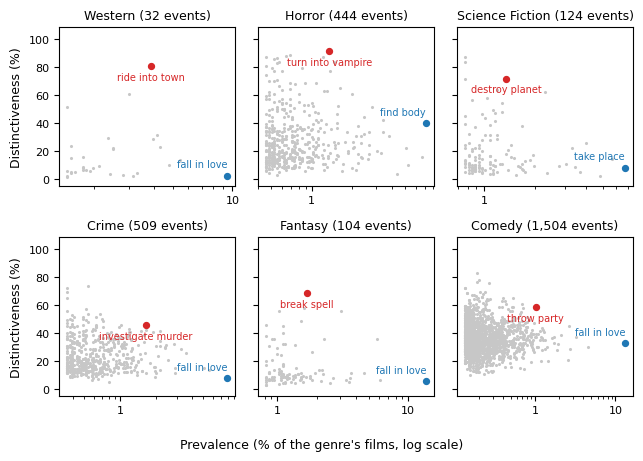

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_events_both_dimensions.pdf')

In [11]:
ev = read_parquet(V4 / '13_event_elements' / 'event_scores.parquet')
fig, axes = plt.subplots(2, 3, figsize=S.size(1.0, 4.6), sharey=True)
out('\nF7. Events on both dimensions')
for ax, g in zip(axes.flat, SIX):
    d = ev[(ev['genre'] == g) & (ev['film_count'] >= 20)]
    ax.scatter(100 * d['prevalence'], 100 * d['distinctiveness'], s=5, color=S.LIGHT, lw=0)
    top_p = d.nlargest(1, 'prevalence').iloc[0]
    cand = d[(d['prevalence'] >= 0.01) & (d['film_count'] >= 8)]
    top_d = cand.nlargest(1, 'distinctiveness').iloc[0]
    for r, col, dy, ha in [(top_p, S.PREVALENCE, 6, 'right'), (top_d, S.DISTINCTIVENESS, -10, 'center')]:
        ax.scatter([100 * r['prevalence']], [100 * r['distinctiveness']], s=18, color=col, zorder=3)
        ax.annotate(r['event'], (100 * r['prevalence'], 100 * r['distinctiveness']), xytext=(0, dy), textcoords='offset points',
                    ha=ha, fontsize=7, color=col)
    ax.set_xscale('log'); ax.set_title(f'{g} ({len(d):,} events)'); ax.set_ylim(-5, 108)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}')); ax.xaxis.set_minor_formatter(plt.NullFormatter())
    out(f'  {g}: {len(d)} events; most prevalent {top_p["event"]} ({100*top_p["prevalence"]:.1f}%, {100*top_p["distinctiveness"]:.0f}%); '
        f'most distinctive {top_d["event"]} ({100*top_d["prevalence"]:.1f}%, {100*top_d["distinctiveness"]:.0f}%)')
for ax in axes[:, 0]:
    ax.set_ylabel('Distinctiveness (%)')
fig.supxlabel("Prevalence (% of the genre's films, log scale)", fontsize=S.FONT_SIZE)
S.save(fig, 'fig_events_both_dimensions', FIG)

## Part IV.F (8): combinations, without the composite

From Notebook 03c's pair table (`combination_stockiness.parquet`): for two narrative elements i and j in genre g, the number of the genre's films that contain both (`joint_count_g`), the number of all films that contain both (`joint_count_corpus`), and the pair's smoothed distinctiveness (`posterior_smoothed`: of the films with both, the share in g, with the same α = 1 smoothing as the single elements).

The rule used here:

- the pair must be in at least max(10, 0.5% of the genre's films) of the genre's films;
- both elements must be narrative nouns or noun phrases in the frozen vocabulary (verbs are left out, so that a combination is a combination of characters, settings, and objects; events are treated separately above);
- pairs whose wordings share a word (e.g., "apach" and "apaches", "rangers" and "texas ranger") are dropped, and a pair that appears under several grammatical types is kept once;
- pairs are ranked by the pair's distinctiveness; ties go to the pair in more films.

The table also gives the higher of the two elements' own distinctiveness in the genre, so the reader can see whether the combination marks the genre more strongly than either element alone. The May 2026 ranking multiplied the composite scores of the two elements by the log of their lift; that is not used.

In [12]:
COLS = ['genre', 'element_i', 'element_type_i', 'element_j', 'element_type_j', 'joint_count_g', 'joint_count_corpus',
        'lift', 'pmi_positive', 'posterior_smoothed']
pairs = pq.read_table(local_copy(V4 / '03c_network' / 'combination_stockiness.parquet'), columns=COLS,
                      filters=[('joint_count_g', '>=', 10)]).to_pandas()
pairs['min_support'] = pairs['genre'].map(lambda g: max(10, math.ceil(0.005 * N_g[g])))
pairs = pairs[pairs['joint_count_g'] >= pairs['min_support']]
pairs = pairs[pairs['element_type_i'].isin(['noun', 'chunk']) & pairs['element_type_j'].isin(['noun', 'chunk'])]
pairs = pairs[[(i, ti) in NARR and (j, tj) in NARR for i, ti, j, tj in
               zip(pairs['element_i'], pairs['element_type_i'], pairs['element_j'], pairs['element_type_j'])]]
def stems(s):
    return {w.lower().rstrip('s') for w in str(s).split()}
a, b = pairs['element_i'].str.lower(), pairs['element_j'].str.lower()
sub = [x in y or y in x or bool(stems(x) & stems(y)) for x, y in zip(a, b)]
pairs = pairs[~np.array(sub)].copy()
pairs['key'] = [' + '.join(sorted([x, y])) for x, y in zip(pairs['element_i'], pairs['element_j'])]
pairs = pairs.sort_values(['posterior_smoothed', 'joint_count_g'], ascending=False).drop_duplicates(['genre', 'key'])
single = sl.set_index(['genre', 'element', 'element_type'])['posterior_smoothed']
def best_single(r):
    return max(single.get((r.genre, r.element_i, r.element_type_i), np.nan), single.get((r.genre, r.element_j, r.element_type_j), np.nan))
out(f'\nF8. Combination pairs passing the support rule: {len(pairs):,}')
topc = pairs.groupby('genre', sort=False).head(5).copy()
topc['best_single'] = [best_single(r) for r in topc.itertuples()]
topc['pct_genre'] = [100 * r.joint_count_g / N_g[r.genre] for r in topc.itertuples()]
topc.to_csv(OUT / 'top_combinations_two_measures.csv', index=False)
rows = []
for g in SIX:
    d = topc[topc['genre'] == g].head(3)
    for i, r in enumerate(d.itertuples()):
        rows.append([tex(g) if i == 0 else '', tex(r.key), f'{r.joint_count_g:,}', f'{100 * r.posterior_smoothed:.0f}', f'{100 * r.best_single:.0f}'])
        out(f'  {g:<16} {r.key:<34} films {r.joint_count_g:>4}  pair {100*r.posterior_smoothed:5.1f}%  best single {100*r.best_single:5.1f}%')
write_table('T-IV-combinations_six', 'Combinations that mark a genre: the three most distinctive pairs in six genres.',
            'tab:combinations', 'llrrr',
            r'Genre & Pair & Films & Pair (\%) & Best single (\%)', rows,
            r'Films: films of the genre whose summary contains both elements. Pair: of all films containing both, the percentage in the genre (smoothed). '
            r'Best single: the higher of the two elements’ own distinctiveness in the genre. Pairs must appear in at least 10 of the genre\'s films or 0.5\% of them, whichever is larger; '
            r'both elements are narrative nouns or noun phrases, and pairs whose wordings share a word are dropped.'.replace(r"\'", "'"))
rows = []
for g in GENRES:
    d = topc[topc['genre'] == g]
    for i, r in enumerate(d.itertuples()):
        rows.append([tex(g) if i == 0 else '', tex(r.key), f'{r.joint_count_g:,}', f'{100 * r.posterior_smoothed:.0f}', f'{100 * r.best_single:.0f}'])
write_table('T-App-B_combinations_17', 'The five most distinctive pairs of elements in each genre.', 'tab:app-combinations', 'llrrr',
            r'Genre & Pair & Films & Pair (\%) & Best single (\%)', rows,
            'Columns and rule as in the combinations table in Part~IV.F of the article.', long=True)


F8. Combination pairs passing the support rule: 177,017
  Western          posse + ranch                      films   42  pair  97.7%  best single  70.8%
  Western          gang + stagecoach                  films   30  pair  96.8%  best single  85.7%
  Western          stagecoach + town                  films   58  pair  96.7%  best single  85.7%
  Horror           cross + vampire                    films   39  pair  97.6%  best single  82.4%
  Horror           horde + zombie                     films   31  pair  97.0%  best single  84.7%
  Horror           attic + corpse                     films   29  pair  96.8%  best single  48.7%
  Science Fiction  crew + starship                    films   21  pair  95.6%  best single  90.7%
  Science Fiction  airlock + crew                     films   20  pair  95.4%  best single  83.4%
  Science Fiction  planet + resistance                films   18  pair  94.9%  best single  73.3%
  Crime            cash + heist                       films  

## Part IV.F (9): co-occurrence networks

For a genre, the nodes are its 80 most distinctive narrative nouns and phrases among those in at least 1% of its films. The links are the 30 strongest pairs among them that pass the same support rule as the combinations, where strength is pointwise mutual information within the genre (how much more often the two elements appear together in the genre's films than chance would predict). Of many candidate layouts, the one with the fewest overlapping labels is drawn.


F9. Networks


  Western: 32 elements, 30 links, overlapping labels 25; strongest: herd + stampede; statehood + territory; foreman + rustler; cattle + herd; cavalry + fort


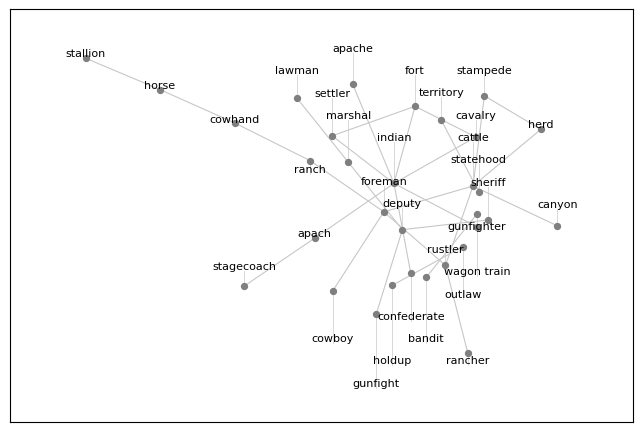

  Crime: 34 elements, 30 links, overlapping labels 31


  Horror: 35 elements, 30 links, overlapping labels 24


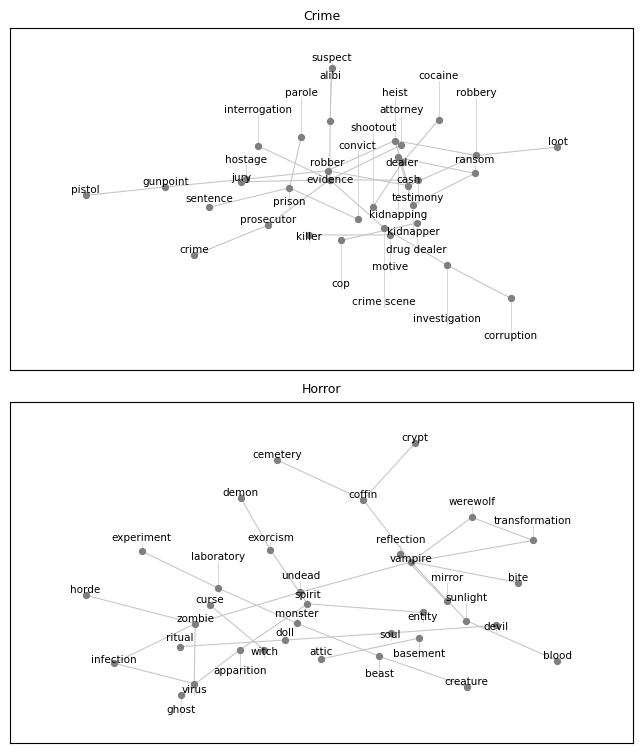

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_networks_crime_horror.pdf')

In [13]:
def label_overlaps(pos, char_w=0.024, line_h=0.075):
    names = list(pos); P = np.array([pos[n] for n in names]); P = (P - P.min(0)) / np.maximum(P.max(0) - P.min(0), 1e-9)
    w = np.array([len(n) for n in names]) * char_w
    dx = np.abs(P[:, None, 0] - P[None, :, 0]); dy = np.abs(P[:, None, 1] - P[None, :, 1])
    hit = (dx < (w[:, None] + w[None, :]) / 2) & (dy < line_h)
    return int((hit.sum() - len(names)) / 2)
def clear_layout(G, tries=300):
    cands = [nx.kamada_kawai_layout(G)]
    for sd in range(tries):
        k = (2.5 + 1.5 * (sd % 3)) / np.sqrt(G.number_of_nodes())
        cands.append(nx.spring_layout(G, k=k, seed=sd, iterations=300))
    return min(cands, key=label_overlaps)
def network(g, n_edges=30, n_nodes=80):
    # nodes: the genre's 80 most distinctive narrative nouns and phrases among those in at least 1% of its films
    d = sl[(sl['genre'] == g) & sl['element_type'].isin(['noun', 'chunk']) & (sl['rel_freq_in_genre'] >= 0.01)]
    keep = set(d.nlargest(n_nodes, 'posterior_smoothed')['element'])
    e = pairs[(pairs['genre'] == g) & pairs['element_i'].isin(keep) & pairs['element_j'].isin(keep)].nlargest(n_edges, 'pmi_positive')
    G = nx.Graph()
    for r in e.itertuples():
        G.add_edge(r.element_i, r.element_j, w=r.pmi_positive)
    return G, e
def spread_labels(pos, char_w=0.024, line_h=0.075, steps=300):
    # move labels (not nodes) apart vertically until no two label boxes overlap
    names = list(pos); P = np.array([pos[n] for n in names], float)
    lo, span = P.min(0), np.maximum(P.max(0) - P.min(0), 1e-9)
    Q = (P - lo) / span
    w = np.array([len(n) for n in names]) * char_w
    L = Q.copy()
    for _ in range(steps):
        moved = False
        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                dx = abs(L[i, 0] - L[j, 0]); dy = L[i, 1] - L[j, 1]
                if dx < (w[i] + w[j]) / 2 and abs(dy) < line_h:
                    push = (line_h - abs(dy)) / 2 + 1e-3
                    sgn = 1 if dy >= 0 else -1
                    L[i, 1] += sgn * push; L[j, 1] -= sgn * push; moved = True
        if not moved:
            break
    return {n: tuple(lo + L[k] * span) for k, n in enumerate(names)}

def draw(ax, G, title=None, font=7):
    pos = clear_layout(G)
    lab = spread_labels(pos)
    nx.draw_networkx_edges(G, pos=pos, ax=ax, edge_color=S.LIGHT, width=0.8)
    nx.draw_networkx_nodes(G, pos=pos, ax=ax, node_size=18, node_color=S.NEUTRAL)
    for n, (x, y) in lab.items():
        if abs(y - pos[n][1]) > 1e-9:   # a label that had to move gets a thin leader line to its node
            ax.plot([pos[n][0], x], [pos[n][1], y], color=S.LIGHT, lw=0.5, zorder=0)
        ax.text(x, y, n, fontsize=font, color=S.INK, ha='center', va='bottom')
    ax.margins(0.1); ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title)
    return label_overlaps(lab)
out('\nF9. Networks')
G, e = network('Western')
fig, ax = plt.subplots(figsize=S.size(1.0, 4.4))
ov = draw(ax, G, font=8)
out(f'  Western: {G.number_of_nodes()} elements, {G.number_of_edges()} links, overlapping labels {ov}; strongest: ' +
    '; '.join(f'{r.element_i} + {r.element_j}' for r in e.head(5).itertuples()))
S.save(fig, 'fig_network_western', FIG)
fig, axes = plt.subplots(2, 1, figsize=S.size(1.0, 7.6))
for ax, g in zip(axes, ['Crime', 'Horror']):
    G, e = network(g)
    ov = draw(ax, G, title=g, font=7.5)
    out(f'  {g}: {G.number_of_nodes()} elements, {G.number_of_edges()} links, overlapping labels {ov}')
S.save(fig, 'fig_networks_crime_horror', FIG)

### Appendix B: one network per genre

In [14]:
for g in GENRES:
    G, e = network(g)
    fig, ax = plt.subplots(figsize=S.size(1.0, 4.0))
    ov = draw(ax, G, font=7)
    S.save(fig, f'fig_app_network_{g.replace(" ", "_")}', FIG, show=False)
    out(f'  Appendix network {g}: {G.number_of_nodes()} elements, {G.number_of_edges()} links, overlapping labels {ov}')

  Appendix network Action: 28 elements, 30 links, overlapping labels 0


  Appendix network Adventure: 29 elements, 30 links, overlapping labels 20


  Appendix network Animation: 26 elements, 30 links, overlapping labels 7


  Appendix network Comedy: 13 elements, 20 links, overlapping labels 0


  Appendix network Crime: 34 elements, 30 links, overlapping labels 31


  Appendix network Drama: 25 elements, 30 links, overlapping labels 14


... (7 outputs left out)

  Appendix network Science Fiction: 32 elements, 30 links, overlapping labels 0


  Appendix network Thriller: 36 elements, 30 links, overlapping labels 33


  Appendix network War: 26 elements, 30 links, overlapping labels 13


  Appendix network Western: 32 elements, 30 links, overlapping labels 25


## Part IV.F (10): centrality in the genre's network, against each measure

Eigenvector centrality of each narrative element in its genre's co-occurrence network (Notebook 03c), against its prevalence and its distinctiveness in the genre, all as percentiles within the genre, for elements in at least 20 of the genre's films, pooled over genres. Shading counts elements (darker = more); the line is the median centrality percentile in each twentieth of the measure. The May 2026 figure plotted centrality against the composite.

/var/folders/3l/l0_mn_f54n54ct0v8g0h24y40000gn/T/ipykernel_75580/4241674635.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rho = cen.groupby('genre').apply(lambda d: pd.Series({'prevalence': spearmanr(d['p_cen'], d['p_prev'])[0],



F10. Centrality vs the two measures (42,963 element-genre pairs, 20+ films)
  mean within-genre Spearman: prevalence 0.87 (range 0.76 to 0.91), distinctiveness 0.00 (range -0.22 to 0.15)


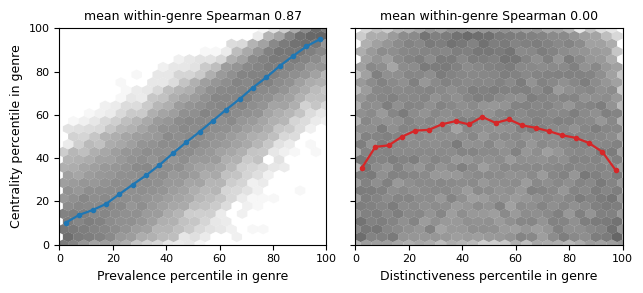

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_centrality_two_measures.pdf')

In [15]:
cen = read_parquet(V4 / '03c_network' / 'element_centrality_by_genre.parquet',
                   columns=['genre', 'element', 'element_type', 'n_films_in_genre', 'eigenvector', 'degree'])
cen = cen.merge(sl, on=['genre', 'element', 'element_type'])
cen = cen[cen['n_films_in_genre'] >= 20].copy()
for c, n in [('eigenvector', 'cen'), ('rel_freq_in_genre', 'prev'), ('posterior_smoothed', 'dist')]:
    cen[f'p_{n}'] = cen.groupby('genre')[c].rank(pct=True)
rho = cen.groupby('genre').apply(lambda d: pd.Series({'prevalence': spearmanr(d['p_cen'], d['p_prev'])[0],
                                                       'distinctiveness': spearmanr(d['p_cen'], d['p_dist'])[0], 'n': len(d)}))
rho.to_csv(OUT / 'centrality_spearman_by_genre.csv')
out(f'\nF10. Centrality vs the two measures ({len(cen):,} element-genre pairs, 20+ films)')
out(f'  mean within-genre Spearman: prevalence {rho["prevalence"].mean():.2f} (range {rho["prevalence"].min():.2f} to {rho["prevalence"].max():.2f}), '
    f'distinctiveness {rho["distinctiveness"].mean():.2f} (range {rho["distinctiveness"].min():.2f} to {rho["distinctiveness"].max():.2f})')
fig, axes = plt.subplots(1, 2, figsize=S.size(1.0, 3.0), sharey=True)
for ax, (m, col, lab) in zip(axes, [('p_prev', S.PREVALENCE, 'Prevalence'), ('p_dist', S.DISTINCTIVENESS, 'Distinctiveness')]):
    ax.hexbin(100 * cen[m], 100 * cen['p_cen'], gridsize=25, cmap=S.CMAP, mincnt=1, linewidths=0, bins='log', alpha=0.6)
    q = pd.cut(cen[m], np.linspace(0, 1, 21))
    med = cen.groupby(q, observed=True)['p_cen'].median()
    ax.plot(100 * np.linspace(0.025, 0.975, 20)[:len(med)], 100 * med.values, '-o', ms=3, color=col, lw=1.6)
    r_ = rho['prevalence' if m == 'p_prev' else 'distinctiveness'].mean()
    ax.set_xlabel(f'{lab} percentile in genre'); ax.set_title(f'mean within-genre Spearman {r_:.2f}')
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
axes[0].set_ylabel('Centrality percentile in genre')
S.save(fig, 'fig_centrality_two_measures', FIG)

## Report

In [16]:
(OUT / 'report.txt').write_text('\n'.join(report) + '\n')
print('wrote', OUT / 'report.txt')
print(sorted(p.name for p in FIG.glob('fig_*') if p.suffix == '.pdf' and not p.name.startswith('fig_study1')))

wrote /Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild/16b_manuscript_figures/report.txt
['fig_app_lifecycles_by_genre.pdf', 'fig_app_network_Action.pdf', 'fig_app_network_Adventure.pdf', 'fig_app_network_Animation.pdf', 'fig_app_network_Comedy.pdf', 'fig_app_network_Crime.pdf', 'fig_app_network_Drama.pdf', 'fig_app_network_Family.pdf', 'fig_app_network_Fantasy.pdf', 'fig_app_network_History.pdf', 'fig_app_network_Horror.pdf', 'fig_app_network_Music.pdf', 'fig_app_network_Mystery.pdf', 'fig_app_network_Romance.pdf', 'fig_app_network_Science_Fiction.pdf', 'fig_app_network_Thriller.pdf', 'fig_app_network_War.pdf', 'fig_app_network_Western.pdf', 'fig_app_survival_by_genre.pdf', 'fig_app_turnover_by_genre.pdf', 'fig_centrality_two_measures.pdf', 'fig_change_points.pdf', 'fig_classifier_check.pdf', 'fig_corpus_genres.pdf', 'fig_court_genre_rank.pdf', 'fig_court_matched.pdf', 'fig_courts_percentiles.p